# Riceify municipality-scale field extraction

This notebook pulls all MAFF rice-field parcels for an official Niigata municipality, then exports and visualizes them.

Current municipality:
- Shibata City
- Local government code: `152064`

Data source:
- MAFF Fude field polygons via Source Cooperative

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import duckdb
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer
import rasterio
from IPython.display import display
from pyproj import Geod, Transformer
from pystac_client import Client
from rasterio.enums import Resampling
from rasterio.windows import from_bounds
from shapely import wkt
from shapely.geometry import mapping

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

In [2]:
FIDE_PARQUET_URL = (
    "https://data.source.coop/pacificspatial/field-polygon-jp/parquet/"
    "jp_field_polygons_2024.parquet"
)
REGION_ID = "shibata_city_152064"
REGION_LABEL = "Shibata City"
LOCAL_GOVERNMENT_CD = "152064"
PLANETARY_COMPUTER_STAC = "https://planetarycomputer.microsoft.com/api/stac/v1"
DEFAULT_DATE_RANGE = "2024-06-01/2024-09-30"
OUTPUT_DIR = Path("outputs") / REGION_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def geodesic_area_m2(geom) -> float:
    geod = Geod(ellps="GRS80")
    area, _ = geod.geometry_area_perimeter(geom)
    return abs(area)


def fetch_region_fields(local_government_cd: str) -> pd.DataFrame:
    con = duckdb.connect()
    con.execute("INSTALL httpfs; LOAD httpfs;")
    con.execute("INSTALL spatial; LOAD spatial;")
    query = f"""
        SELECT
            polygon_uuid,
            point_lng,
            point_lat,
            local_government_cd,
            land_type_en,
            ST_AsText(GEOM) AS wkt
        FROM read_parquet('{FIDE_PARQUET_URL}')
        WHERE local_government_cd = '{local_government_cd}'
          AND land_type_en = 'rice_field'
    """
    return con.execute(query).fetchdf()


def build_geojson(df: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    features = []
    rows = []
    for row in df.itertuples(index=False):
        geom = wkt.loads(row.wkt)
        area_m2 = geodesic_area_m2(geom)
        simplified = geom.simplify(0.00001, preserve_topology=True)
        rows.append(
            {
                "field_id": row.polygon_uuid,
                "local_government_cd": str(row.local_government_cd),
                "land_type_en": row.land_type_en,
                "point_lng": row.point_lng,
                "point_lat": row.point_lat,
                "area_m2": area_m2,
            }
        )
        features.append(
            {
                "type": "Feature",
                "properties": {
                    "field_id": row.polygon_uuid,
                    "local_government_cd": str(row.local_government_cd),
                    "land_type_en": row.land_type_en,
                    "area_m2": round(area_m2, 2),
                    "point_lng": row.point_lng,
                    "point_lat": row.point_lat,
                },
                "geometry": mapping(simplified),
            }
        )
    return {"type": "FeatureCollection", "features": features}, pd.DataFrame(rows)


def create_map(geojson: dict, bbox: list[float], summary_df: pd.DataFrame) -> folium.Map:
    west, south, east, north = bbox
    center = [(south + north) / 2, (west + east) / 2]
    area_ha = summary_df["area_m2"].sum() / 10000.0

    fmap = folium.Map(location=center, zoom_start=11, tiles="CartoDB positron")
    folium.GeoJson(
        geojson,
        name="Rice field parcels",
        style_function=lambda feature: {
            "color": "#2a7f62",
            "weight": 0.45,
            "fillColor": "#9ed8a6",
            "fillOpacity": 0.14,
        },
        highlight_function=lambda feature: {
            "color": "#14532d",
            "weight": 1.2,
            "fillOpacity": 0.24,
        },
        tooltip=folium.GeoJsonTooltip(
            fields=["field_id", "area_m2", "local_government_cd"],
            aliases=["Field ID", "Area (m2)", "Municipality code"],
            sticky=False,
            labels=True,
        ),
    ).add_to(fmap)

    folium.Rectangle(
        bounds=[[south, west], [north, east]],
        color="#1d4ed8",
        weight=1,
        fill=False,
        dash_array="6,4",
        tooltip=f"{REGION_LABEL} rice-field extent",
    ).add_to(fmap)

    title_html = f"""
    <div style="
        position: fixed;
        top: 14px;
        left: 50px;
        z-index: 9999;
        background: rgba(255,255,255,0.92);
        border: 1px solid rgba(15,23,42,0.12);
        border-radius: 8px;
        padding: 12px 14px;
        font-family: Arial, sans-serif;
        box-shadow: 0 8px 24px rgba(15,23,42,0.12);
    ">
        <div style="font-size: 16px; font-weight: 700;">{REGION_LABEL} rice fields</div>
        <div style="font-size: 12px; margin-top: 4px;">Region ID: {REGION_ID}</div>
        <div style="font-size: 12px;">Municipality code: {LOCAL_GOVERNMENT_CD}</div>
        <div style="font-size: 12px;">Fields: {len(summary_df):,}</div>
        <div style="font-size: 12px;">Total mapped rice area: {area_ha:,.1f} ha</div>
    </div>
    """
    fmap.get_root().html.add_child(folium.Element(title_html))
    fmap.fit_bounds([[south, west], [north, east]])
    folium.LayerControl(collapsed=False).add_to(fmap)
    return fmap


def search_sentinel_scene(bbox: list[float], date_range: str = DEFAULT_DATE_RANGE):
    catalog = Client.open(PLANETARY_COMPUTER_STAC)
    search = catalog.search(
        collections=["sentinel-2-l2a"],
        bbox=bbox,
        datetime=date_range,
        query={"eo:cloud_cover": {"lt": 30}},
        max_items=25,
    )
    items = list(search.items())
    if not items:
        raise RuntimeError("No Sentinel-2 L2A scenes found for this municipality extent.")
    items.sort(key=lambda item: item.properties.get("eo:cloud_cover", 1000))
    return planetary_computer.sign(items[0])


def read_bbox_preview(asset_href: str, bbox: list[float], out_size: int = 384) -> np.ndarray:
    with rasterio.open(asset_href) as src:
        transformer = Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
        west, south = transformer.transform(bbox[0], bbox[1])
        east, north = transformer.transform(bbox[2], bbox[3])
        left, right = sorted([west, east])
        bottom, top = sorted([south, north])
        window = from_bounds(left, bottom, right, top, src.transform).round_offsets().round_lengths()
        height = max(1, int(window.height))
        width = max(1, int(window.width))
        scale = max(height, width) / float(out_size)
        out_height = max(1, int(round(height / scale)))
        out_width = max(1, int(round(width / scale)))
        arr = src.read(
            1,
            window=window,
            out_shape=(out_height, out_width),
            resampling=Resampling.bilinear,
        ).astype("float32")
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        return arr / 10000.0


def normalized_difference(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    denom = a + b
    out = np.full(a.shape, np.nan, dtype="float32")
    valid = np.isfinite(a) & np.isfinite(b) & (np.abs(denom) > 1e-6)
    out[valid] = (a[valid] - b[valid]) / denom[valid]
    return out


def build_band_previews(item, bbox: list[float]) -> tuple[dict[str, np.ndarray], dict[str, str]]:
    band_arrays = {}
    band_titles = {
        "B02": "Blue (490nm)",
        "B03": "Green (560nm)",
        "B04": "Red (665nm)",
        "B05": "Red edge 1",
        "B06": "Red edge 2",
        "B07": "Red edge 3",
        "B08": "NIR (842nm)",
        "B11": "SWIR 1",
        "B12": "SWIR 2",
    }
    for band_name in band_titles:
        band_arrays[band_name] = read_bbox_preview(item.assets[band_name].href, bbox)
    band_arrays["NDVI"] = normalized_difference(band_arrays["B08"], band_arrays["B04"])
    band_titles["NDVI"] = "NDVI"
    return band_arrays, band_titles


def plot_band_maps(band_arrays: dict[str, np.ndarray], band_titles: dict[str, str]):
    specs = [
        ("B02", "Blues"),
        ("B03", "Greens"),
        ("B04", "Reds"),
        ("B08", "Purples"),
        ("B05", "cividis"),
        ("B06", "cividis"),
        ("B07", "cividis"),
        ("B11", "magma"),
        ("B12", "magma"),
        ("NDVI", "RdYlGn"),
    ]
    fig, axes = plt.subplots(4, 3, figsize=(13, 15), constrained_layout=True)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (band_name, cmap) in zip(axes.flat, specs):
        arr = band_arrays[band_name]
        if band_name == "NDVI":
            vmin, vmax = -0.2, 0.9
        else:
            vmin = float(np.nanpercentile(arr, 2))
            vmax = float(np.nanpercentile(arr, 98))
        im = ax.imshow(arr, cmap=cmap, vmin=vmin, vmax=vmax)
        ax.set_title(band_titles[band_name])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return fig


## Run extraction and build the map

This cell fetches every `rice_field` parcel in Shibata City, saves the artifacts to `outputs/shibata_city_152064`, and renders the interactive map inline.

/var/folders/nq/fgtn3c5x05j3pqdp995xj56c0000gn/T/ipykernel_4449/3333868153.py:165: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  arr = src.read(


,region_id,region_label,local_government_cd,bbox,field_count,total_area_m2,field_polygon_source,sentinel_scene_id,sentinel_datetime,sentinel_cloud_cover_pct
0,shibata_city_152064,Shibata City,152064,"[139.242384074, 37.815631729, 139.478532365, 3...",36875,90813535.107889,https://data.source.coop/pacificspatial/field-...,S2A_MSIL2A_20240620T012701_R074_T54SUH_2024062...,2024-06-20T01:27:01.024000+00:00,0.001218


,scene_id,datetime,cloud_cover_pct
0,S2A_MSIL2A_20240620T012701_R074_T54SUH_2024062...,2024-06-20T01:27:01.024000+00:00,0.001218


,field_id,local_government_cd,land_type_en,point_lng,point_lat,area_m2
0,2d91ecc1-6ad0-4a2e-9a29-48c88d167f2b,152064,rice_field,139.280748,37.953131,684.438192
1,38c432c6-8b55-44ed-936a-40dfe4fac426,152064,rice_field,139.329743,37.882500,683.947636
2,1f157644-e7a3-45b1-ab5b-988c2561ce2a,152064,rice_field,139.355352,37.998403,683.604080
3,b21c0b5d-a406-4aa4-94c2-1a9a19273cf9,152064,rice_field,139.278401,37.874727,683.607149
4,dcfe899e-ca91-4e90-9261-17c4c355caed,152064,rice_field,139.357169,37.916988,683.402078
5,6ff17875-6d6c-43e9-8063-ce594740d73a,152064,rice_field,139.341451,37.891054,682.858429
6,8a2084b2-22b9-475e-9fbf-66ce2afc6255,152064,rice_field,139.293659,37.951357,682.385733
7,79f920a0-0607-4110-a024-d2de58efda80,152064,rice_field,139.349260,37.902744,682.202296
8,23072626-c7d6-4206-9a71-611289d69a62,152064,rice_field,139.287404,37.896314,609.537333
9,18577392-a083-4aca-bd79-8b1b5701d3fd,152064,rice_field,139.262833,37.917685,704.286814


,area_m2
count,36875.000000
mean,2462.739935
std,2618.556370
min,20.729244
25%,868.883648
50%,1612.985924
75%,2930.801774
max,68434.114445


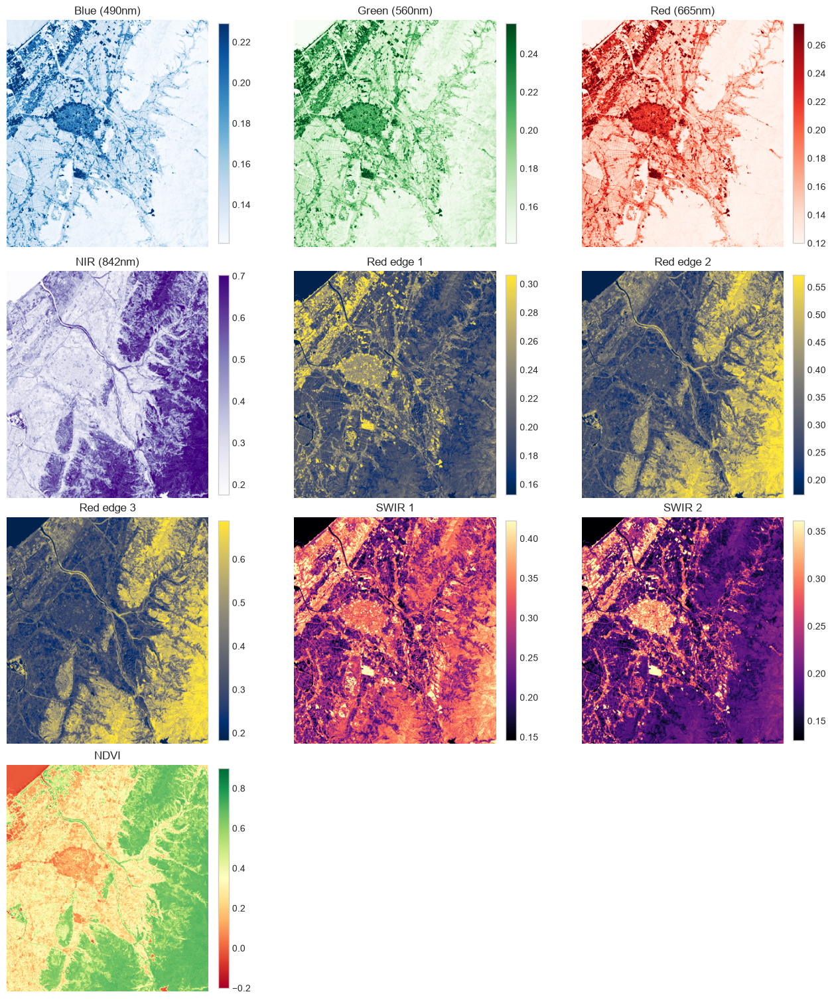

In [3]:
fields_df = fetch_region_fields(LOCAL_GOVERNMENT_CD)
geojson, summary_df = build_geojson(fields_df)

bbox = [
    float(summary_df["point_lng"].min()),
    float(summary_df["point_lat"].min()),
    float(summary_df["point_lng"].max()),
    float(summary_df["point_lat"].max()),
]

sentinel_item = search_sentinel_scene(bbox)
band_arrays, band_titles = build_band_previews(sentinel_item, bbox)

metadata = {
    "region_id": REGION_ID,
    "region_label": REGION_LABEL,
    "local_government_cd": LOCAL_GOVERNMENT_CD,
    "bbox": bbox,
    "field_count": int(len(summary_df)),
    "total_area_m2": float(summary_df["area_m2"].sum()),
    "field_polygon_source": FIDE_PARQUET_URL,
    "sentinel_scene_id": sentinel_item.id,
    "sentinel_datetime": sentinel_item.datetime.isoformat(),
    "sentinel_cloud_cover_pct": float(sentinel_item.properties.get("eo:cloud_cover", float("nan"))),
}

(OUTPUT_DIR / "region_fields.geojson").write_text(json.dumps(geojson), encoding="utf-8")
summary_df.to_csv(OUTPUT_DIR / "region_field_summary.csv", index=False)
(OUTPUT_DIR / "region_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

fmap = create_map(geojson, bbox, summary_df)
fmap.save(str(OUTPUT_DIR / "region_fields_map.html"))
band_fig = plot_band_maps(band_arrays, band_titles)
band_fig.savefig(OUTPUT_DIR / "region_band_maps.png", dpi=180)

display(pd.DataFrame([metadata]))
display(pd.DataFrame([{
    "scene_id": sentinel_item.id,
    "datetime": sentinel_item.datetime.isoformat(),
    "cloud_cover_pct": sentinel_item.properties.get("eo:cloud_cover"),
}]))
display(summary_df.head(20))
display(summary_df["area_m2"].describe().to_frame(name="area_m2"))
plt.show()
fmap

## Saved outputs

Running the notebook refreshes:
- `outputs/shibata_city_152064/region_fields.geojson`
- `outputs/shibata_city_152064/region_field_summary.csv`
- `outputs/shibata_city_152064/region_metadata.json`
- `outputs/shibata_city_152064/region_fields_map.html`
- `outputs/shibata_city_152064/region_band_maps.png`